# Lab 5 — Bài tập mục 9

Nguyễn Đình Huy — MSSV: 2474802010140

Mỗi mục/bài có một cell code, có thể chạy từ thư mục Lab hoặc `code/`. Giữ hai CSV trong `data/`; trên Colab có thể tải CSV vào thư mục hiện tại. Hình lưu vào `figures/`. Chạy `scripts/run_all.py` để cập nhật notebook và xuất nhật ký vào `outputs/`.

## Bài tập 1 — Tự vẽ cây

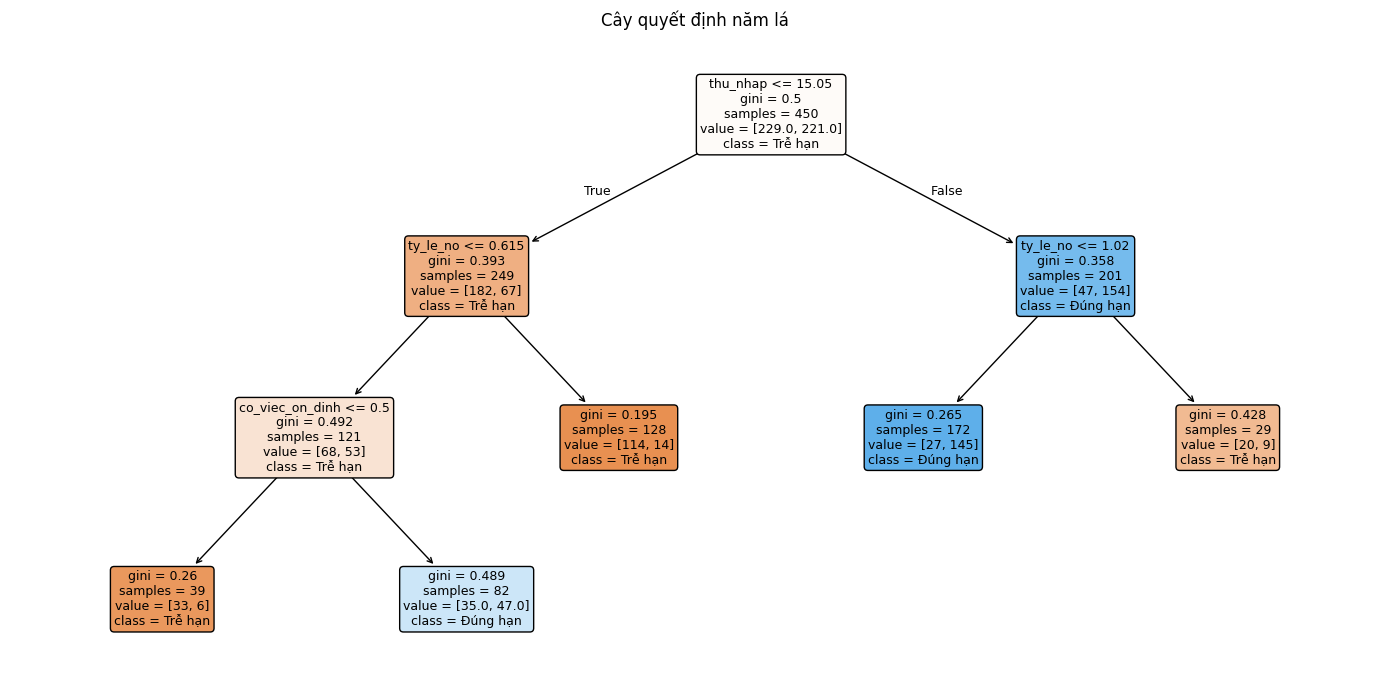

Đã lưu figures/cay_nam_la.png: độ sâu 3, số lá 5.


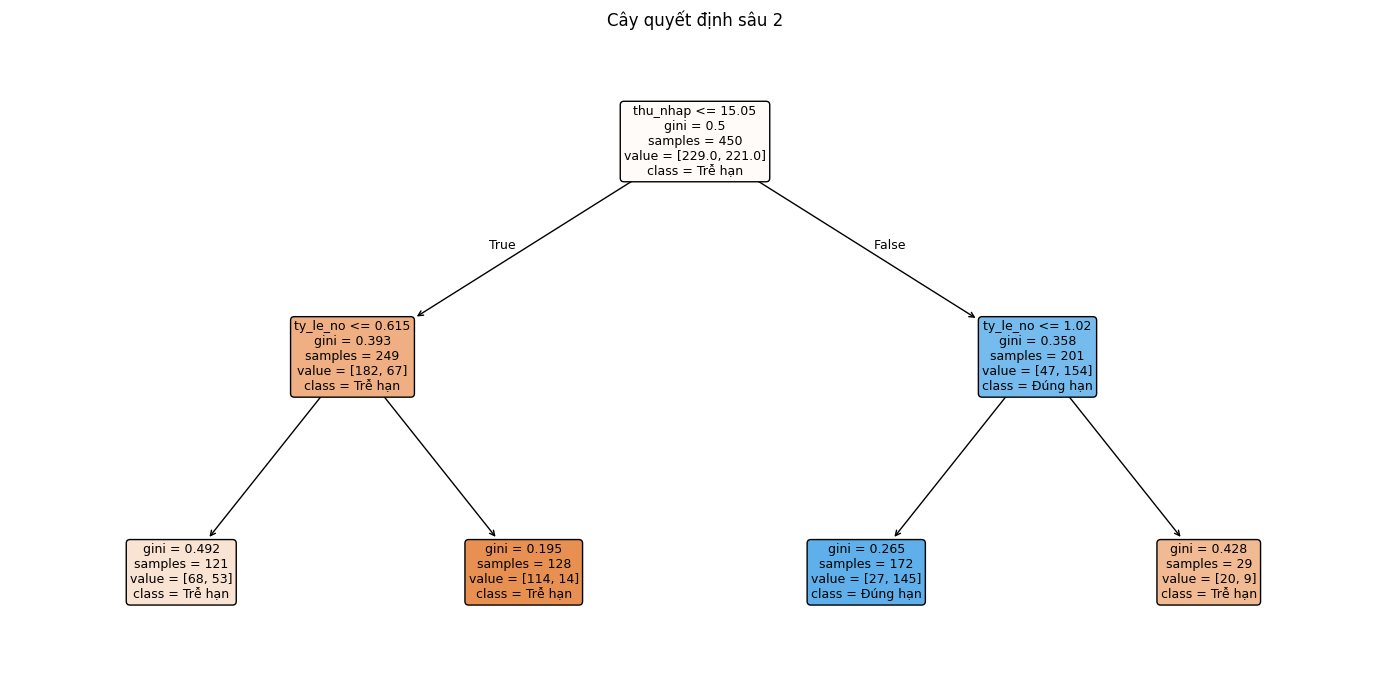

Đã lưu figures/cay_sau_2.png: độ sâu 2, số lá 4.
Lá trái 1: lớp 0, Gini = 0.4923, số khách = 121.
Lá trái 2: lớp 0, Gini = 0.1948, số khách = 128.
Gini tại nút trước khi chia: 0.3933; sau chia: 0.3394.
Hai lá bên trái cùng kết luận trễ hạn (lớp 0), nhưng tỷ lệ hai lớp khác nhau.
Cây vẫn chia vì Gini trung bình có trọng số giảm; mục tiêu của phép chia là làm các nút thuần hơn, không bắt buộc đổi nhãn dự đoán.


In [1]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; cũng nhận CSV tải trực tiếp lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "khach_vay.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ thư mục data/ hoặc tải CSV lên thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

df = pd.read_csv(tep_du_lieu("khach_vay.csv"))
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
# Giữ nguyên 450 mẫu học, 150 mẫu kiểm tra và tỷ lệ hai lớp như tài liệu.
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

cay_nam_la = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0).fit(X_tr, y_tr)
cay_sau_2 = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_tr, y_tr)
for cay, ten, tieu_de in [
    (cay_nam_la, "cay_nam_la.png", "Cây quyết định năm lá"),
    (cay_sau_2, "cay_sau_2.png", "Cây quyết định sâu 2"),
]:
    plt.figure(figsize=(14, 7))
    plot_tree(cay, feature_names=list(X.columns), class_names=["Trễ hạn", "Đúng hạn"],
              filled=True, rounded=True, precision=3, fontsize=9)
    plt.title(tieu_de)
    plt.tight_layout()
    plt.savefig(thu_muc_hinh / ten, dpi=150)
    plt.show()
    plt.close()
    print(f"Đã lưu figures/{ten}: độ sâu {cay.get_depth()}, số lá {cay.get_n_leaves()}.")

# Hai con của nhánh trái là hai lá khi max_depth=2.
cau_truc = cay_sau_2.tree_
nut_trai = cau_truc.children_left[0]
hai_la = [cau_truc.children_left[nut_trai], cau_truc.children_right[nut_trai]]
for so, la in enumerate(hai_la, start=1):
    nhan = cay_sau_2.classes_[np.argmax(cau_truc.value[la][0])]
    print(f"Lá trái {so}: lớp {nhan}, Gini = {cau_truc.impurity[la]:.4f}, "
          f"số khách = {cau_truc.n_node_samples[la]}.")
gini_sau = sum(cau_truc.n_node_samples[la] * cau_truc.impurity[la] for la in hai_la)
gini_sau /= cau_truc.n_node_samples[nut_trai]
print(f"Gini tại nút trước khi chia: {cau_truc.impurity[nut_trai]:.4f}; sau chia: {gini_sau:.4f}.")
print("Hai lá bên trái cùng kết luận trễ hạn (lớp 0), nhưng tỷ lệ hai lớp khác nhau.")
print("Cây vẫn chia vì Gini trung bình có trọng số giảm; mục tiêu của phép chia là làm các nút thuần hơn, không bắt buộc đổi nhãn dự đoán.")


## Bài tập 2 — Tự tìm câu hỏi gốc trên dữ liệu thật

In [2]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; cũng nhận CSV tải trực tiếp lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "khach_vay.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ thư mục data/ hoặc tải CSV lên thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv(tep_du_lieu("khach_vay.csv"))
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
# Giữ nguyên 450 mẫu học, 150 mẫu kiểm tra và tỷ lệ hai lớp như tài liệu.
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

def gini(nhan):
    if len(nhan) == 0:
        return 0.0
    p1 = np.asarray(nhan).mean()
    return 1 - p1**2 - (1 - p1)**2

def tim_cau_hoi(X, y):
    """Thử mọi cột và trung điểm giữa hai giá trị khác nhau liên tiếp."""
    nhan = np.asarray(y)
    gini_goc = gini(nhan)
    giam_tot_nhat = -np.inf
    cot_tot_nhat, nguong_tot_nhat = None, None
    for ten_cot in X.columns:
        gia_tri = X[ten_cot].to_numpy()
        cac_muc = np.unique(gia_tri)
        for muc_truoc, muc_sau in zip(cac_muc[:-1], cac_muc[1:]):
            nguong = (muc_truoc + muc_sau) / 2
            di_trai = gia_tri <= nguong
            ty_le_trai = di_trai.mean()
            sau_chia = ty_le_trai * gini(nhan[di_trai]) + (1 - ty_le_trai) * gini(nhan[~di_trai])
            giam = gini_goc - sau_chia
            if giam > giam_tot_nhat:
                giam_tot_nhat = giam
                cot_tot_nhat, nguong_tot_nhat = ten_cot, nguong
    return cot_tot_nhat, nguong_tot_nhat

cot, nguong = tim_cau_hoi(X_tr, y_tr)
di_trai = X_tr[cot].to_numpy() <= nguong
nhan = y_tr.to_numpy()
goc = gini(nhan)
sau = di_trai.mean() * gini(nhan[di_trai]) + (~di_trai).mean() * gini(nhan[~di_trai])
print(f"Số khách dùng để tìm câu hỏi: {len(X_tr)}")
print(f"Câu hỏi tốt nhất: {cot} <= {nguong:.2f}")
print(f"Gini gốc = {goc:.6f}; sau chia = {sau:.6f}; giảm = {goc - sau:.6f}")
cay = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
cot_sklearn = X_tr.columns[cay.tree_.feature[0]]
nguong_sklearn = cay.tree_.threshold[0]
print(f"scikit-learn: {cot_sklearn} <= {nguong_sklearn:.2f}")
assert cot == cot_sklearn and np.isclose(nguong, nguong_sklearn)
print("Kết quả khớp câu hỏi gốc của cây: thu nhập với ngưỡng 15.05 triệu đồng.")
print("Chỉ cần thử trung điểm các giá trị liên tiếp vì mọi ngưỡng trong cùng khoảng tạo ra cùng hai nhóm.")
print("Chọn câu hỏi làm Gini giảm nhiều nhất, có tính trọng số số khách ở hai nhánh; không dùng tập kiểm tra để chọn câu hỏi.")


Số khách dùng để tìm câu hỏi: 450
Câu hỏi tốt nhất: thu_nhap <= 15.05
Gini gốc = 0.499842; sau chia = 0.377697; giảm = 0.122145
scikit-learn: thu_nhap <= 15.05
Kết quả khớp câu hỏi gốc của cây: thu nhập với ngưỡng 15.05 triệu đồng.
Chỉ cần thử trung điểm các giá trị liên tiếp vì mọi ngưỡng trong cùng khoảng tạo ra cùng hai nhóm.
Chọn câu hỏi làm Gini giảm nhiều nhất, có tính trọng số số khách ở hai nhánh; không dùng tập kiểm tra để chọn câu hỏi.


## Bài tập 3 — Gini hay entropy

Cây tự do (gini): sâu 13, 92 lá; accuracy học 1.0000, kiểm tra 0.7667
Độ sâu   Accuracy học   CV 5 phần
     1   0.7467         0.7244
     2   0.7711         0.7378
     3   0.8000         0.7511
     4   0.8644         0.8089
     5   0.8978         0.8333
     6   0.9133         0.8156


     7   0.9400         0.8067


     8   0.9600         0.7733


     9   0.9800         0.7800
    10   0.9911         0.7822
    11   0.9933         0.7756
    12   0.9978         0.7778
    13   1.0000         0.7733
    14   1.0000         0.7733


    15   1.0000         0.7733
Chọn gini: độ sâu 5, CV 0.8333, accuracy kiểm tra 0.8533.

Cây tự do (entropy): sâu 13, 88 lá; accuracy học 1.0000, kiểm tra 0.7667
Độ sâu   Accuracy học   CV 5 phần


     1   0.7467         0.7244
     2   0.7711         0.7133


     3   0.7733         0.7489
     4   0.8511         0.8111
     5   0.8956         0.8222
     6   0.9111         0.8222
     7   0.9378         0.8089
     8   0.9533         0.7933


     9   0.9778         0.7844
    10   0.9867         0.7978


    11   0.9933         0.7911


    12   0.9978         0.7822
    13   1.0000         0.7822
    14   1.0000         0.7822
    15   1.0000         0.7867
Chọn entropy: độ sâu 5, CV 0.8222, accuracy kiểm tra 0.8467.

Entropy chênh -0.67 điểm phần trăm accuracy so với Gini trên cùng tập kiểm tra.
Ở lần chia này, đổi sang entropy làm kết quả khác rất ít: cả hai chọn độ sâu 5, entropy dự đoán đúng ít hơn Gini 1 trong 150 khách kiểm tra.
Nếu nhiều độ sâu có cùng điểm CV cao nhất, chọn độ sâu xuất hiện đầu tiên trong dãy tăng dần, giống cách dùng max trong tài liệu.


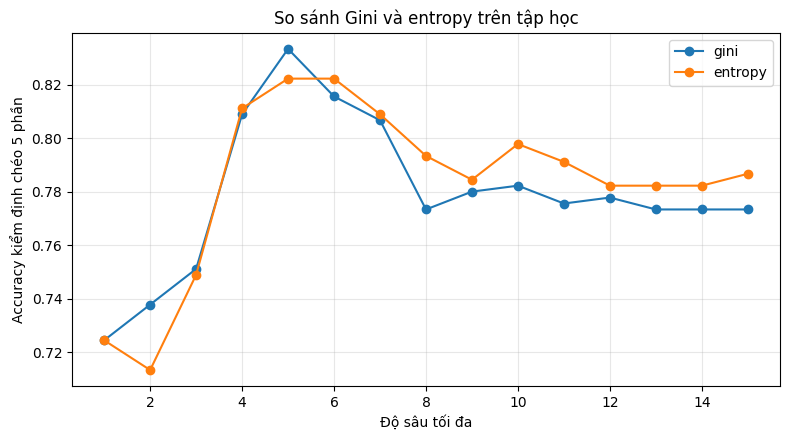

In [3]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; cũng nhận CSV tải trực tiếp lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "khach_vay.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ thư mục data/ hoặc tải CSV lên thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv(tep_du_lieu("khach_vay.csv"))
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
# Giữ nguyên 450 mẫu học, 150 mẫu kiểm tra và tỷ lệ hai lớp như tài liệu.
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

ket_qua = {}
diem_ve = {}
for tieu_chi in ["gini", "entropy"]:
    tu_do = DecisionTreeClassifier(criterion=tieu_chi, random_state=0).fit(X_tr, y_tr)
    print(f"Cây tự do ({tieu_chi}): sâu {tu_do.get_depth()}, {tu_do.get_n_leaves()} lá; "
          f"accuracy học {accuracy_score(y_tr, tu_do.predict(X_tr)):.4f}, "
          f"kiểm tra {accuracy_score(y_te, tu_do.predict(X_te)):.4f}")
    print("Độ sâu   Accuracy học   CV 5 phần")
    diem = {}
    for do_sau in range(1, 16):
        cay = DecisionTreeClassifier(criterion=tieu_chi, max_depth=do_sau, random_state=0)
        diem[do_sau] = cross_val_score(cay, X_tr, y_tr, cv=5).mean()
        cay.fit(X_tr, y_tr)
        print(f"{do_sau:6d}   {accuracy_score(y_tr, cay.predict(X_tr)):.4f}         {diem[do_sau]:.4f}")
    do_sau_tot = max(diem, key=diem.get)
    cay_tot = DecisionTreeClassifier(criterion=tieu_chi, max_depth=do_sau_tot, random_state=0).fit(X_tr, y_tr)
    accuracy = accuracy_score(y_te, cay_tot.predict(X_te))
    ket_qua[tieu_chi] = (do_sau_tot, diem[do_sau_tot], accuracy)
    diem_ve[tieu_chi] = diem
    print(f"Chọn {tieu_chi}: độ sâu {do_sau_tot}, CV {diem[do_sau_tot]:.4f}, accuracy kiểm tra {accuracy:.4f}.")
    print()
chenh_lech = ket_qua["entropy"][2] - ket_qua["gini"][2]
print(f"Entropy chênh {chenh_lech * 100:+.2f} điểm phần trăm accuracy so với Gini trên cùng tập kiểm tra.")
print("Ở lần chia này, đổi sang entropy làm kết quả khác rất ít: cả hai chọn độ sâu 5, entropy dự đoán đúng ít hơn Gini 1 trong 150 khách kiểm tra.")
print("Nếu nhiều độ sâu có cùng điểm CV cao nhất, chọn độ sâu xuất hiện đầu tiên trong dãy tăng dần, giống cách dùng max trong tài liệu.")

plt.figure(figsize=(8, 4.5))
for ten, diem in diem_ve.items():
    plt.plot(list(diem), list(diem.values()), "o-", label=ten)
plt.xlabel("Độ sâu tối đa")
plt.ylabel("Accuracy kiểm định chéo 5 phần")
plt.title("So sánh Gini và entropy trên tập học")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(thu_muc_hinh / "gini_va_entropy.png", dpi=150)
plt.show()
plt.close()


## Bài tập 4 — Cắt tỉa bằng số khách tối thiểu ở lá

min_samples_leaf   CV 5 phần
               1   0.7733
               2   0.7822
               5   0.8067
              10   0.8089
              20   0.8089
              40   0.7133
Chọn min_samples_leaf = 10, CV = 0.8089.
Cây được chọn: độ sâu 8, số lá 30.
Accuracy kiểm tra của cây giới hạn số khách ở lá: 0.8467
Accuracy kiểm tra của cây sâu 5: 0.8533
Trên bộ dữ liệu và lần chia này, giới hạn độ sâu 5 cho accuracy cao hơn giới hạn số khách tối thiểu ở lá.
Giới hạn kích thước lá tránh những quyết định chỉ dựa trên rất ít khách, còn giới hạn độ sâu chặn số lần hỏi liên tiếp.


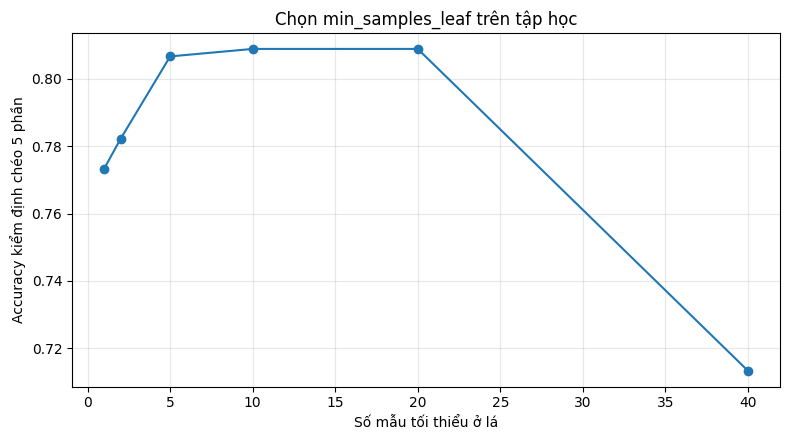

In [4]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; cũng nhận CSV tải trực tiếp lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "khach_vay.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ thư mục data/ hoặc tải CSV lên thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv(tep_du_lieu("khach_vay.csv"))
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
# Giữ nguyên 450 mẫu học, 150 mẫu kiểm tra và tỷ lệ hai lớp như tài liệu.
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

diem = {}
print("min_samples_leaf   CV 5 phần")
for so_khach in [1, 2, 5, 10, 20, 40]:
    cay = DecisionTreeClassifier(min_samples_leaf=so_khach, random_state=0)
    diem[so_khach] = cross_val_score(cay, X_tr, y_tr, cv=5).mean()
    print(f"{so_khach:16d}   {diem[so_khach]:.4f}")
# Chọn bằng CV trên tập học; nếu bằng điểm thì lấy giá trị đầu tiên trong danh sách.
# Sau đó chỉ chấm cấu hình đã chọn trên tập kiểm tra.
so_khach_tot = max(diem, key=diem.get)
cay_tot = DecisionTreeClassifier(min_samples_leaf=so_khach_tot, random_state=0).fit(X_tr, y_tr)
accuracy_la = accuracy_score(y_te, cay_tot.predict(X_te))
cay_sau_5 = DecisionTreeClassifier(max_depth=5, random_state=0).fit(X_tr, y_tr)
accuracy_sau = accuracy_score(y_te, cay_sau_5.predict(X_te))
print(f"Chọn min_samples_leaf = {so_khach_tot}, CV = {diem[so_khach_tot]:.4f}.")
print(f"Cây được chọn: độ sâu {cay_tot.get_depth()}, số lá {cay_tot.get_n_leaves()}.")
print(f"Accuracy kiểm tra của cây giới hạn số khách ở lá: {accuracy_la:.4f}")
print(f"Accuracy kiểm tra của cây sâu 5: {accuracy_sau:.4f}")
if accuracy_la > accuracy_sau:
    print("Trên bộ dữ liệu và lần chia này, giới hạn số khách tối thiểu ở lá cho accuracy cao hơn giới hạn độ sâu 5.")
elif accuracy_la < accuracy_sau:
    print("Trên bộ dữ liệu và lần chia này, giới hạn độ sâu 5 cho accuracy cao hơn giới hạn số khách tối thiểu ở lá.")
else:
    print("Trên bộ dữ liệu và lần chia này, hai cách giới hạn cây cho accuracy bằng nhau.")
print("Giới hạn kích thước lá tránh những quyết định chỉ dựa trên rất ít khách, còn giới hạn độ sâu chặn số lần hỏi liên tiếp.")

plt.figure(figsize=(8, 4.5))
plt.plot(list(diem), list(diem.values()), "o-")
plt.xlabel("Số mẫu tối thiểu ở lá")
plt.ylabel("Accuracy kiểm định chéo 5 phần")
plt.title("Chọn min_samples_leaf trên tập học")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(thu_muc_hinh / "chon_so_khach_o_la.png", dpi=150)
plt.show()
plt.close()


## Bài tập 5 — Độ quan trọng bằng cách xáo trộn

Độ quan trọng của năm cột (sắp theo permutation mean):
                       MDI  Permutation mean  Permutation std
thu_nhap            0.4269            0.3073           0.0242
ty_le_no            0.2696            0.1993           0.0357
co_viec_on_dinh     0.0773            0.1117           0.0155
so_nguoi_phu_thuoc  0.0764            0.0497           0.0199
so_ngau_nhien       0.1499            0.0017           0.0111
Cột ngẫu nhiên: hạng 3/5 theo feature_importances_, hạng 5/5 theo permutation importance.
Xáo trộn cột ngẫu nhiên làm accuracy giảm trung bình 0.0017.
feature_importances_ cộng mức giảm độ hỗn tạp trên tập học, nên cột có nhiều giá trị khác nhau có nhiều cơ hội tách tình cờ và được điểm cao.
Permutation importance đo mức giảm accuracy trên tập kiểm tra khi xáo trộn một cột. Cột ngẫu nhiên không chứa tín hiệu dự đoán ổn định nên mức giảm nhỏ, có thể bằng 0 hoặc âm do dao động mẫu.
Độ quan trọng phản ánh cách mô hình sử dụng dữ liệu, không chứng minh quan hệ nhân quả.


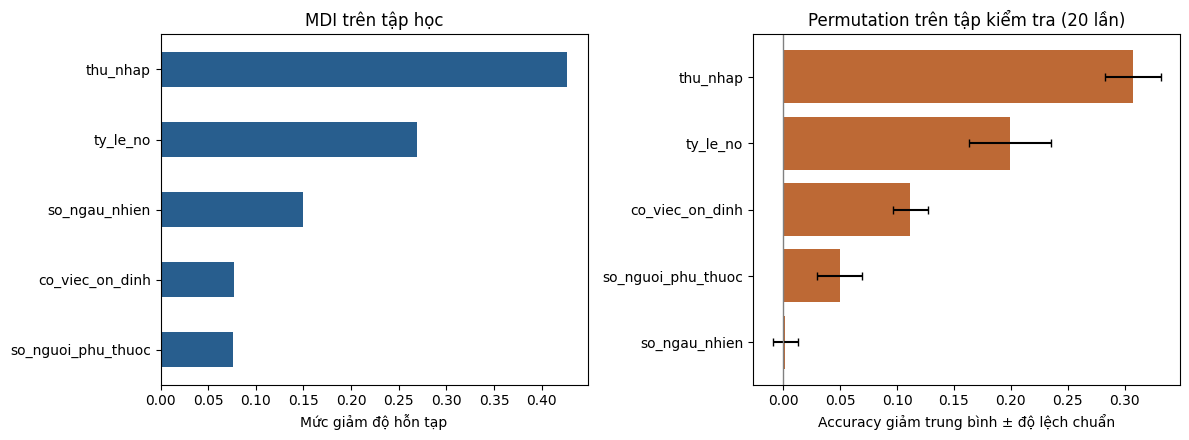

In [5]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; cũng nhận CSV tải trực tiếp lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "khach_vay.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ thư mục data/ hoặc tải CSV lên thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

df = pd.read_csv(tep_du_lieu("khach_vay.csv"))
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
# Giữ nguyên 450 mẫu học, 150 mẫu kiểm tra và tỷ lệ hai lớp như tài liệu.
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

rng = np.random.default_rng(0)
X_tr_nn, X_te_nn = X_tr.copy(), X_te.copy()
# Sinh tập học trước như mục 7; tiếp tục bộ sinh để tạo cột độc lập cho tập kiểm tra.
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))
X_te_nn["so_ngau_nhien"] = rng.random(len(X_te))
rung = RandomForestClassifier(n_estimators=200, random_state=0).fit(X_tr_nn, y_tr)
do_giam_gini = pd.Series(rung.feature_importances_, index=X_tr_nn.columns)
hoan_vi = permutation_importance(rung, X_te_nn, y_te, n_repeats=20, random_state=0)
trung_binh = pd.Series(hoan_vi.importances_mean, index=X_te_nn.columns)
do_lech_chuan = pd.Series(hoan_vi.importances_std, index=X_te_nn.columns)
bang = pd.DataFrame({"MDI": do_giam_gini, "Permutation mean": trung_binh,
                     "Permutation std": do_lech_chuan})
print("Độ quan trọng của năm cột (sắp theo permutation mean):")
print(bang.sort_values("Permutation mean", ascending=False).round(4).to_string())
# Đồng hạng nếu các giá trị bằng nhau.
hang_gini = int(do_giam_gini.rank(ascending=False, method="min")["so_ngau_nhien"])
hang_hoan_vi = int(trung_binh.rank(ascending=False, method="min")["so_ngau_nhien"])
print(f"Cột ngẫu nhiên: hạng {hang_gini}/5 theo feature_importances_, hạng {hang_hoan_vi}/5 theo permutation importance.")
print(f"Xáo trộn cột ngẫu nhiên làm accuracy giảm trung bình {trung_binh['so_ngau_nhien']:.4f}.")
print("feature_importances_ cộng mức giảm độ hỗn tạp trên tập học, nên cột có nhiều giá trị khác nhau có nhiều cơ hội tách tình cờ và được điểm cao.")
print("Permutation importance đo mức giảm accuracy trên tập kiểm tra khi xáo trộn một cột. Cột ngẫu nhiên không chứa tín hiệu dự đoán ổn định nên mức giảm nhỏ, có thể bằng 0 hoặc âm do dao động mẫu.")
print("Độ quan trọng phản ánh cách mô hình sử dụng dữ liệu, không chứng minh quan hệ nhân quả.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
do_giam_gini.sort_values().plot.barh(ax=axes[0], color="#285e8e")
axes[0].set_title("MDI trên tập học")
axes[0].set_xlabel("Mức giảm độ hỗn tạp")
sap_xep = trung_binh.sort_values()
axes[1].barh(sap_xep.index, sap_xep, xerr=do_lech_chuan[sap_xep.index], color="#bd6935", capsize=3)
axes[1].axvline(0, color="gray", linewidth=1)
axes[1].set_title("Permutation trên tập kiểm tra (20 lần)")
axes[1].set_xlabel("Accuracy giảm trung bình ± độ lệch chuẩn")
fig.tight_layout()
fig.savefig(thu_muc_hinh / "permutation_importance.png", dpi=150)
plt.show()
plt.close(fig)


## Bài tập 6 — Rừng cho bài toán hồi quy

Mô hình          MAE kiểm tra (tỷ đồng)   Giá 250 m² (tỷ đồng)
Cây sâu 3        0.5039                    9.4025
Đường thẳng      0.2578                    19.9139


Rừng 200 cây     0.4559                    9.1973
Mô hình có MAE thấp nhất trong so sánh: Đường thẳng.
Rừng giảm MAE so với cây sâu 3 (0.4559 so với 0.5039 tỷ đồng), nhưng vẫn kém đường thẳng (0.2578 tỷ đồng) trên tập kiểm tra này.
Rừng dự đoán 150 m²: 9.1973; 250 m²: 9.1973 tỷ đồng.
Rừng không ngoại suy tiếp xu hướng tăng: mỗi cây trả trung bình giá các mẫu học ở lá, rồi rừng lấy trung bình dự đoán của các cây.
Các diện tích lớn hơn mọi mẫu học đều đi vào lá ngoài cùng của từng cây, nên giá dự đoán giữ nguyên thay vì tăng theo diện tích.


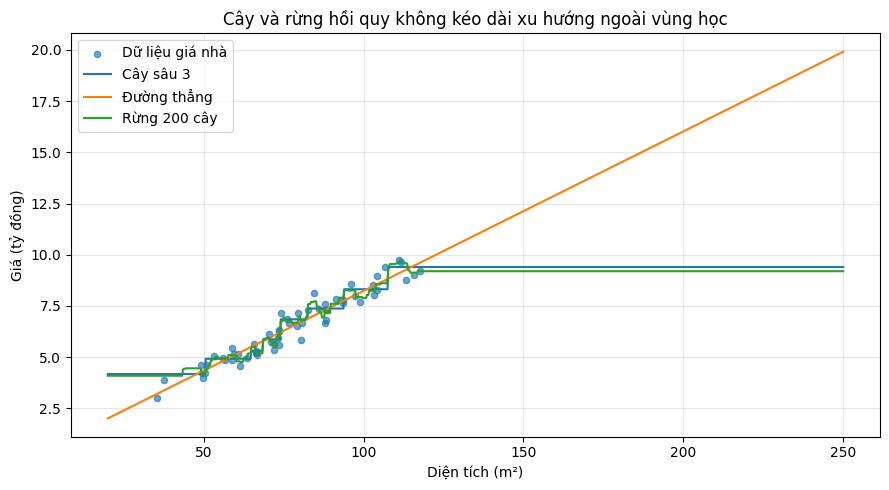

In [6]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; cũng nhận CSV tải trực tiếp lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "khach_vay.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ thư mục data/ hoặc tải CSV lên thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

df = pd.read_csv(tep_du_lieu("gia_nha.csv"))
X = df[["dien_tich"]]
y = df["gia"]
# Cùng cách chia với bài 1 để so sánh công bằng.
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42
)

cac_mo_hinh = {
    "Cây sâu 3": DecisionTreeRegressor(max_depth=3, random_state=0),
    "Đường thẳng": LinearRegression(),
    "Rừng 200 cây": RandomForestRegressor(n_estimators=200, random_state=0),
}
can_moi = pd.DataFrame({"dien_tich": [150.0, 250.0]})
diem_mae = {}
print("Mô hình          MAE kiểm tra (tỷ đồng)   Giá 250 m² (tỷ đồng)")
for ten, mo_hinh in cac_mo_hinh.items():
    mo_hinh.fit(X_tr, y_tr)
    diem_mae[ten] = mean_absolute_error(y_te, mo_hinh.predict(X_te))
    gia_250 = mo_hinh.predict(can_moi)[1]
    print(f"{ten:16s} {diem_mae[ten]:.4f}                    {gia_250:.4f}")
print(f"Mô hình có MAE thấp nhất trong so sánh: {min(diem_mae, key=diem_mae.get)}.")
print("Rừng giảm MAE so với cây sâu 3 (0.4559 so với 0.5039 tỷ đồng), nhưng vẫn kém đường thẳng (0.2578 tỷ đồng) trên tập kiểm tra này.")
rung = cac_mo_hinh["Rừng 200 cây"]
gia_150, gia_250 = rung.predict(can_moi)
print(f"Rừng dự đoán 150 m²: {gia_150:.4f}; 250 m²: {gia_250:.4f} tỷ đồng.")
print("Rừng không ngoại suy tiếp xu hướng tăng: mỗi cây trả trung bình giá các mẫu học ở lá, rồi rừng lấy trung bình dự đoán của các cây.")
print("Các diện tích lớn hơn mọi mẫu học đều đi vào lá ngoài cùng của từng cây, nên giá dự đoán giữ nguyên thay vì tăng theo diện tích.")

luoi = pd.DataFrame({"dien_tich": np.linspace(20, 250, 1000)})
plt.figure(figsize=(9, 5))
plt.scatter(X["dien_tich"], y, alpha=0.65, s=20, label="Dữ liệu giá nhà")
for ten, mo_hinh in cac_mo_hinh.items():
    plt.plot(luoi["dien_tich"], mo_hinh.predict(luoi), label=ten)
plt.xlabel("Diện tích (m²)")
plt.ylabel("Giá (tỷ đồng)")
plt.title("Cây và rừng hồi quy không kéo dài xu hướng ngoài vùng học")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(thu_muc_hinh / "rung_hoi_quy.png", dpi=150)
plt.show()
plt.close()
